# Dye fading rates

Fit a first-order decay at each temperature.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/decay.csv")
df.head()

,temp_c,time_min,absorbance
0,25,0,0.9878
1,25,5,0.8596
2,25,10,0.7407
3,25,15,0.6249
4,25,20,0.5308


In [3]:
rates = {}
for temp, group in df.groupby("temp_c"):
    slope, _ = np.polyfit(group["time_min"], np.log(group["absorbance"]), 1)
    rates[int(temp)] = -slope
k_25 = rates[25]
k_45 = rates[45]
for temp, k in rates.items():
    print(f"{temp} C: k = {k:.4f} 1/min")

25 C: k = 0.0308 1/min
35 C: k = 0.0621 1/min
45 C: k = 0.1183 1/min


In [4]:
speedup = k_45 / k_25
print(f"Going from 25 to 45 C speeds fading up {speedup:.2f}x")

Going from 25 to 45 C speeds fading up 3.84x


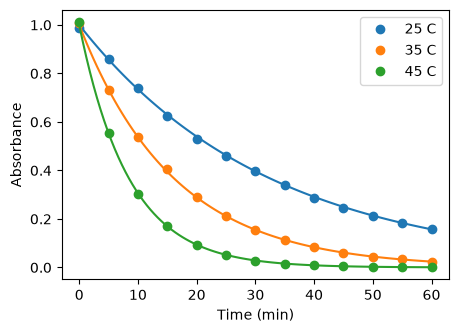

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for temp, group in df.groupby("temp_c"):
    ax.plot(group["time_min"], group["absorbance"], "o", label=f"{temp} C")
    t = np.linspace(0, 60, 100)
    ax.plot(t, np.exp(-rates[temp] * t), "-", color=ax.lines[-1].get_color())
ax.set_xlabel("Time (min)")
ax.set_ylabel("Absorbance")
ax.legend()

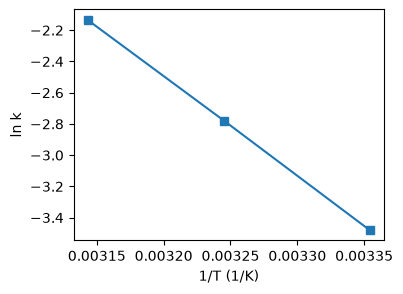

In [7]:
inv_t = [1 / (t + 273.15) for t in rates]
plt.figure(figsize=(4, 3))
plt.plot(inv_t, np.log(list(rates.values())), "s-")
plt.xlabel("1/T (1/K)")
plt.ylabel("ln k")
plt.show()

In [8]:
summary = pd.DataFrame(
    {
        "T (C)": list(rates),
        "k (1/min)": list(rates.values()),
        "Half-life (min)": [np.log(2) / k for k in rates.values()],
        "Faded at 60 min": [1 - np.exp(-k * 60) for k in rates.values()],
    }
)
summary

,T (C),k (1/min),Half-life (min),Faded at 60 min
0,25,0.030837,22.478076,0.842794
1,35,0.062072,11.166840,0.975870
2,45,0.118289,5.859767,0.999173


In [9]:
# Changed after the fit, so a value saved after 'fit' keeps the fitted one
k_25 = 0
k899 = 777.555